# CPR Rotor 3D & nD 测试示例

本 Notebook 演示 3D 和 nD Rotor 模块的功能：

1. **Rotor3D** — 四元数 3D 旋转器
2. **RotorClifford** — Clifford 代数 nD 旋转器
3. **3D/nD 几何分析** — 曲率、挠率、弧长
4. **3D 可视化** — matplotlib 3D / plotly 3D

---

In [1]:
# 环境准备
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# 导入 rotor 模块
from cprdspy.rotor import (
    Rotor2D, RotorComposition,
    Rotor3D, Rotor3DComposition,
    RotorClifford, RotorCliffordComposition,
    trace, trace_nd,
    compute_curvature, compute_curvature_nd,
    compute_torsion_3d,
    arc_length_nd, total_length_nd,
    rotor_plot, rotor_plot_3d, rotor_plot_3d_mpl, rotor_plot_3d_plotly,
)

print("All modules imported successfully")

All modules imported successfully


## 1. Rotor3D 基础

3D 旋转器表示三维空间中的圆周运动：

$$
R(r, \omega, \varphi; t) = r \cdot [\cos(\omega t + \varphi) \cdot e_1 + \sin(\omega t + \varphi) \cdot e_2]
$$

其中 $e_1, e_2$ 是旋转平面内的两个正交单位向量。

In [2]:
# 创建一个 3D Rotor (XY 平面内的圆)
r = Rotor3D(radius=3, frequency=1, phase=0, e1=[1,0,0], e2=[0,1,0])
print(f"Rotor: {r}")

# 计算不同时刻的位置
t_values = [0, np.pi/4, np.pi/2, np.pi]
print("\nPosition R(t):")
for t in t_values:
    pos = r.evaluate(t)
    print(f"  t={t:.4f} -> ({pos[0]:.4f}, {pos[1]:.4f}, {pos[2]:.4f})")

Rotor: 3 * [cos(1t)*e1 + sin(1t)*e2]

Position R(t):
  t=0.0000 -> (3.0000, 0.0000, 0.0000)
  t=0.7854 -> (2.1213, 2.1213, 0.0000)
  t=1.5708 -> (0.0000, 3.0000, 0.0000)
  t=3.1416 -> (-3.0000, 0.0000, 0.0000)


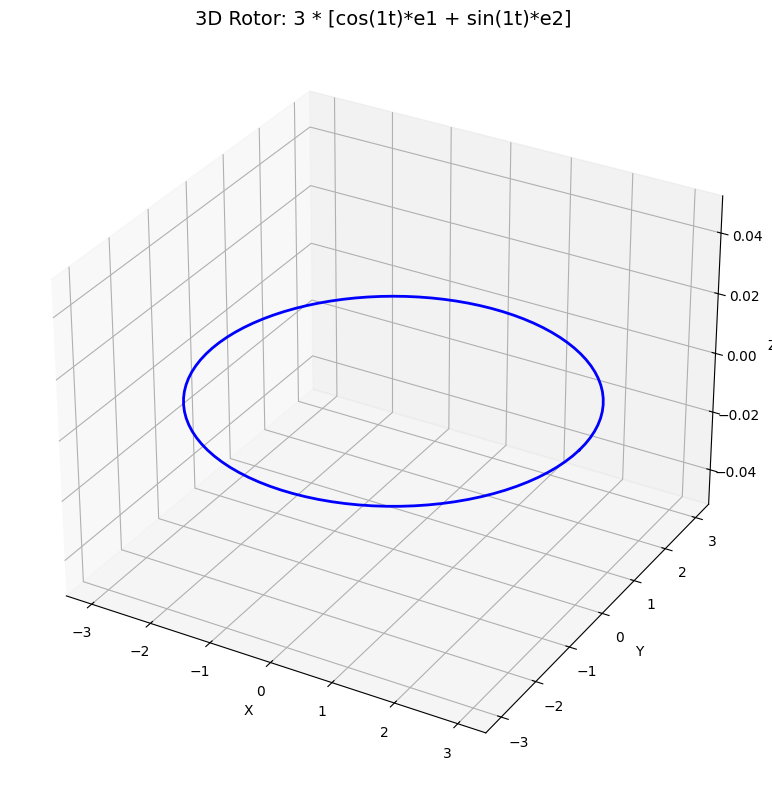

A single 3D Rotor traces a circle in 3D space


In [3]:
# 可视化：单个 3D Rotor 的轨迹
t = np.linspace(0, 2*np.pi, 100)
pos = r.evaluate(t)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(pos[:, 0], pos[:, 1], pos[:, 2], 'b-', lw=2)
ax.set_title(f'3D Rotor: {r}', fontsize=14)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

print("A single 3D Rotor traces a circle in 3D space")

## 2. Rotor3DComposition — 3D 运动组合

In [4]:
# 两个 3D Rotor 叠加
curve3d = Rotor3D(3, 1, 0, [1,0,0], [0,1,0]) + Rotor3D(1, 5, 0, [0,1,0], [0,0,1])
print(f"Curve: {curve3d}")
print(f"Frequencies: {curve3d.frequencies()}")
print(f"Is closed: {curve3d.is_closed()}")
print(f"Period: {curve3d.period():.6f}")

Curve: 3 * [cos(1t)*e1 + sin(1t)*e2] + 1 * [cos(5t)*e1 + sin(5t)*e2]
Frequencies: [1, 5]
Is closed: True
Period: 6.283185


In [5]:
# 采样 3D 曲线
t, x, y, z = trace_nd(curve3d, n_points=1000)

print(f"Sample points: {len(t)}")
print(f"X range: [{x.min():.4f}, {x.max():.4f}]")
print(f"Y range: [{y.min():.4f}, {y.max():.4f}]")
print(f"Z range: [{z.min():.4f}, {z.max():.4f}]")

Sample points: 1000
X range: [-3.0000, 3.0000]
Y range: [-3.8685, 3.8686]
Z range: [-1.0000, 1.0000]


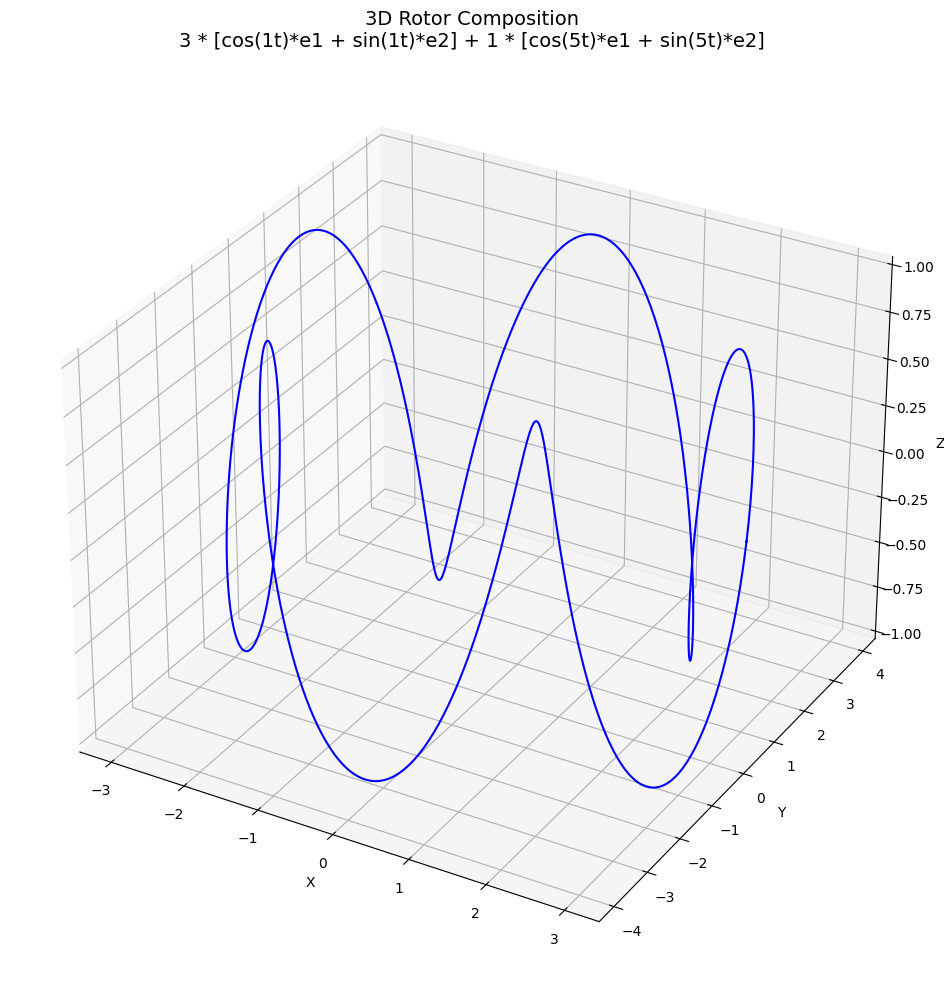

In [6]:
# 可视化 3D 曲线
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, 'b-', lw=1.5)
ax.set_title(f'3D Rotor Composition\n{curve3d}', fontsize=14)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

## 3. 3D 几何分析

In [7]:
# 计算曲率 (GA 公式)
kappa = compute_curvature_nd(x, y, z, t=t)

print(f"Curvature κ:")
print(f"  Range: [{kappa.min():.4f}, {kappa.max():.4f}]")
print(f"  Mean: {kappa.mean():.4f}")

# 计算挠率
torsion = compute_torsion_3d(x, y, z, t=t)

print(f"\nTorsion τ:")
print(f"  Range: [{torsion.min():.4f}, {torsion.max():.4f}]")
print(f"  Mean: {torsion.mean():.4f}")

# 计算弧长
L = total_length_nd(x, y, z, t=t)
print(f"\nTotal arc length: {L:.4f}")

Curvature κ:
  Range: [0.3173, 4.6652]
  Mean: 0.9812

Torsion τ:
  Range: [-0.8121, 0.8121]
  Mean: 0.0001

Total arc length: 35.5595


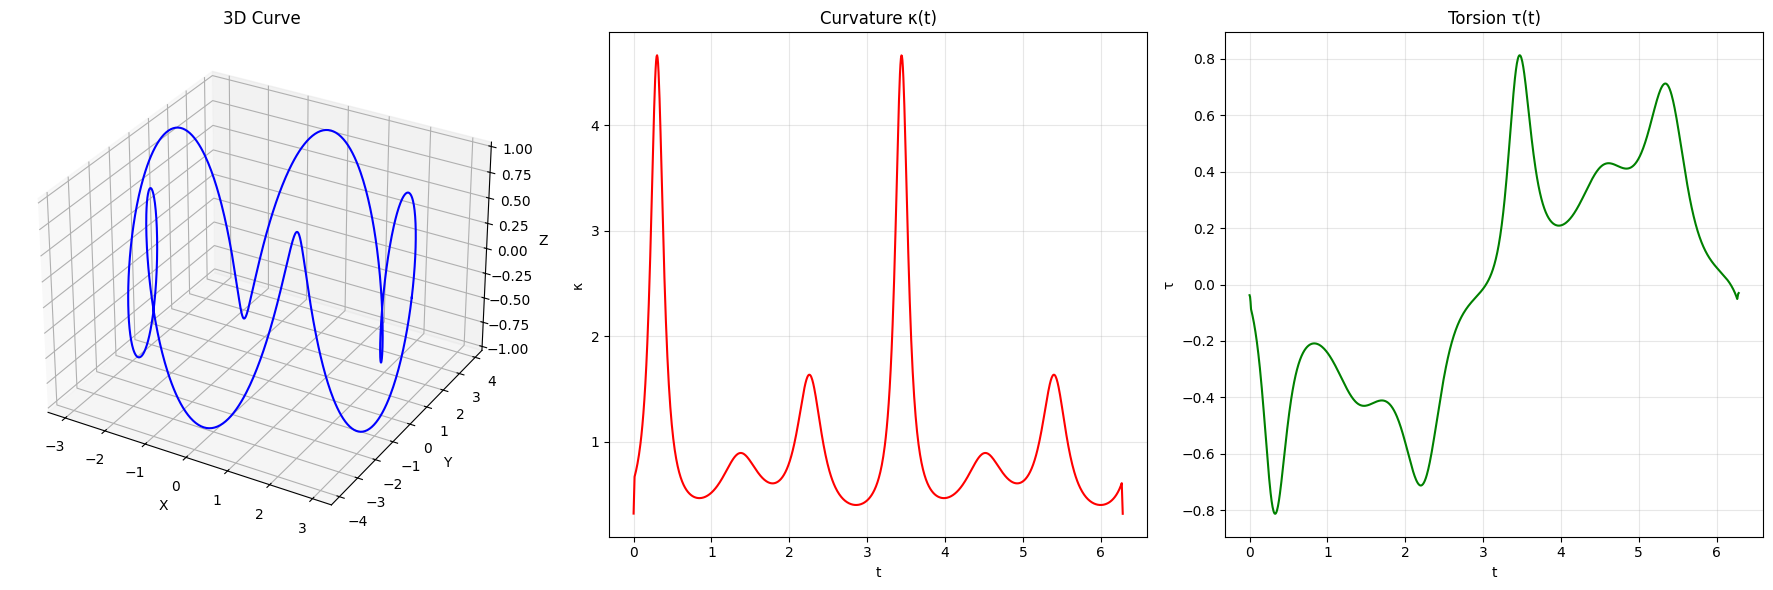

In [8]:
# 可视化：曲线 + 曲率 + 挠率
fig = plt.figure(figsize=(18, 6))

# 3D 曲线
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot(x, y, z, 'b-', lw=1.5)
ax1.set_title('3D Curve', fontsize=12)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

# 曲率
ax2 = fig.add_subplot(132)
ax2.plot(t, kappa, 'r-', lw=1.5)
ax2.set_title('Curvature κ(t)', fontsize=12)
ax2.set_xlabel('t')
ax2.set_ylabel('κ')
ax2.grid(True, alpha=0.3)

# 挠率
ax3 = fig.add_subplot(133)
ax3.plot(t, torsion, 'g-', lw=1.5)
ax3.set_title('Torsion τ(t)', fontsize=12)
ax3.set_xlabel('t')
ax3.set_ylabel('τ')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. RotorClifford — nD 旋转器

使用 Clifford 代数实现任意维度的旋转器：

$$
R(t) = r \cdot \exp(-B \cdot (\omega t + \varphi)/2) \cdot e_1 \cdot \exp(B \cdot (\omega t + \varphi)/2)
$$

其中 $B = e_1 \wedge e_2$ 是旋转平面的单位二重向量。

In [9]:
# 3D Clifford Rotor (与 Rotor3D 等价)
r_clifford = RotorClifford(3, 1, 0, [1,0,0], [0,1,0], n_dim=3)
pos = r_clifford.evaluate(0)
print(f"Clifford R(0) = {pos}")
print(f"Expected: [3, 0, 0]")

pos2 = r_clifford.evaluate(np.pi/2)
print(f"\nClifford R(pi/2) = {pos2}")
print(f"Expected: [0, 3, 0]")

Clifford R(0) = [3. 0. 0.]
Expected: [3, 0, 0]

Clifford R(pi/2) = [-9.07607323e-14  3.00000000e+00  0.00000000e+00]
Expected: [0, 3, 0]


In [10]:
# 4D Clifford Rotor
r4d = RotorClifford(2, 1, 0, [1,0,0,0], [0,1,0,0], n_dim=4)
print(f"4D Rotor: {r4d}")

pos4d = r4d.evaluate(0)
print(f"\nR4D(0) = {pos4d}")
print(f"Expected: [2, 0, 0, 0]")

pos4d_2 = r4d.evaluate(np.pi/2)
print(f"\nR4D(pi/2) = {pos4d_2}")
print(f"Expected: [0, 2, 0, 0]")

4D Rotor: 2 * [cos(1t)*e1 + sin(1t)*e2]

R4D(0) = [2. 0. 0. 0.]
Expected: [2, 0, 0, 0]

R4D(pi/2) = [-6.05071548e-14  2.00000000e+00  0.00000000e+00  0.00000000e+00]
Expected: [0, 2, 0, 0]


In [11]:
# 4D 曲线组合
curve4d = (RotorClifford(2, 1, 0, [1,0,0,0], [0,1,0,0], n_dim=4) + 
           RotorClifford(1, 3, 0, [0,0,1,0], [0,0,0,1], n_dim=4))

print(f"4D Curve: {curve4d}")
print(f"Frequencies: {curve4d.frequencies()}")
print(f"Is closed: {curve4d.is_closed()}")
print(f"Period: {curve4d.period():.6f}")

4D Curve: 2 * [cos(1t)*e1 + sin(1t)*e2] + 1 * [cos(3t)*e1 + sin(3t)*e2]
Frequencies: [1, 3]
Is closed: True
Period: 6.283185


In [12]:
# 采样 4D 曲线
t, x, y, z, w = trace_nd(curve4d, n_points=500)

print(f"Sample points: {len(t)}")
print(f"X range: [{x.min():.4f}, {x.max():.4f}]")
print(f"Y range: [{y.min():.4f}, {y.max():.4f}]")
print(f"Z range: [{z.min():.4f}, {z.max():.4f}]")
print(f"W range: [{w.min():.4f}, {w.max():.4f}]")

# 计算 4D 曲率
kappa4d = compute_curvature_nd(x, y, z, w, t=t)
print(f"\n4D Curvature κ:")
print(f"  Range: [{kappa4d.min():.4f}, {kappa4d.max():.4f}]")
print(f"  Mean: {kappa4d.mean():.4f}")

Sample points: 500
X range: [-2.0000, 2.0000]
Y range: [-2.0000, 2.0000]
Z range: [-1.0000, 1.0000]
W range: [-1.0000, 1.0000]

4D Curvature κ:
  Range: [0.3545, 0.7091]
  Mean: 0.7070


## 5. 3D 可视化

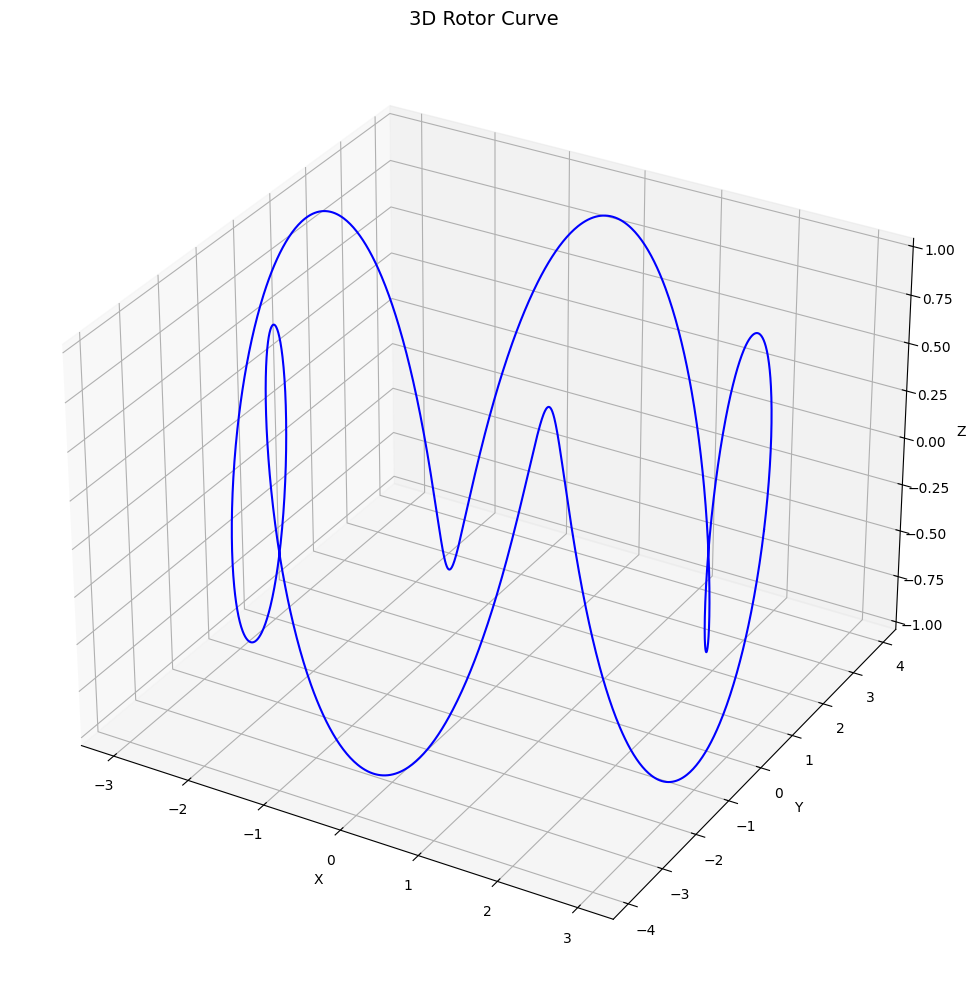

<Axes3D: title={'center': '3D Rotor Curve'}, xlabel='X', ylabel='Y', zlabel='Z'>

In [13]:
# matplotlib 3D 绘图
curve3d = Rotor3D(3, 1, 0, [1,0,0], [0,1,0]) + Rotor3D(1, 5, 0, [0,1,0], [0,0,1])
rotor_plot_3d_mpl(curve3d, title='3D Rotor Curve')

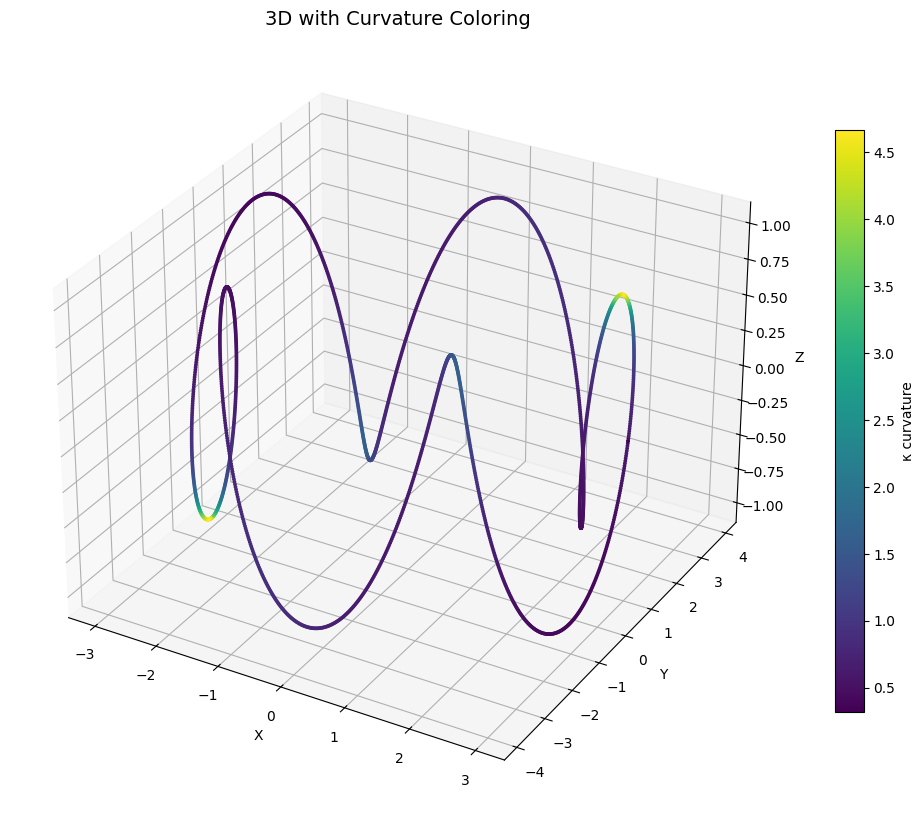

<Axes3D: title={'center': '3D with Curvature Coloring'}, xlabel='X', ylabel='Y', zlabel='Z'>

In [14]:
# 按曲率着色
rotor_plot_3d_mpl(curve3d, color_by='curvature', title='3D with Curvature Coloring')

In [15]:
# plotly 3D 交互图
fig = rotor_plot_3d_plotly(curve3d, title='3D Rotor (Plotly)', show=False)
fig.write_html('rotor_3d_demo.html')
print("Saved: rotor_3d_demo.html")
fig.show()

Saved: rotor_3d_demo.html


## 6. 经典 3D 曲线

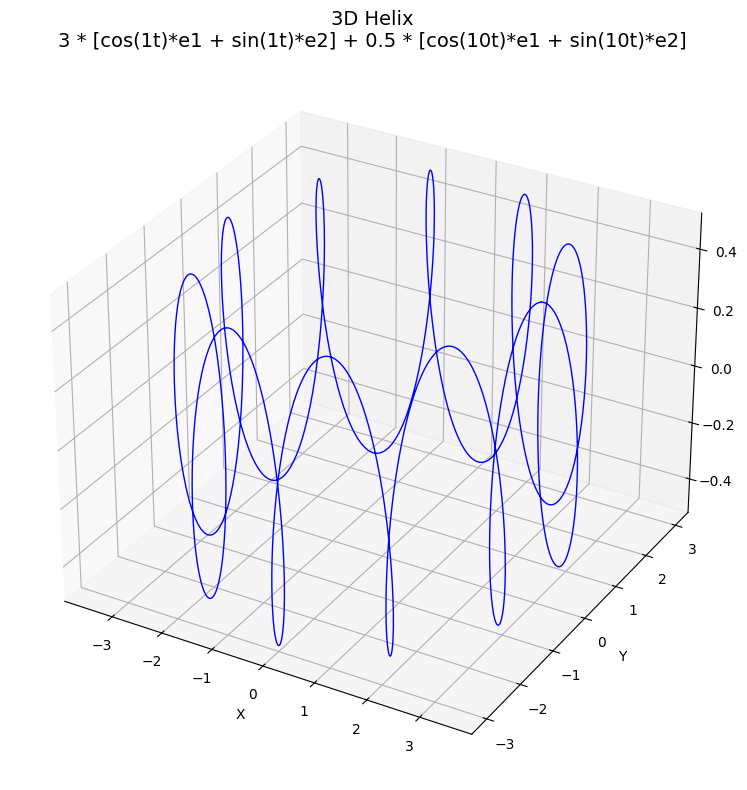

In [16]:
# 3D 螺旋线
helix = Rotor3D(3, 1, 0, [1,0,0], [0,1,0]) + Rotor3D(0.5, 10, 0, [0,0,1], [1,0,0])
t, x, y, z = trace_nd(helix, n_points=2000)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, 'b-', lw=1)
ax.set_title(f'3D Helix\n{helix}', fontsize=14)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

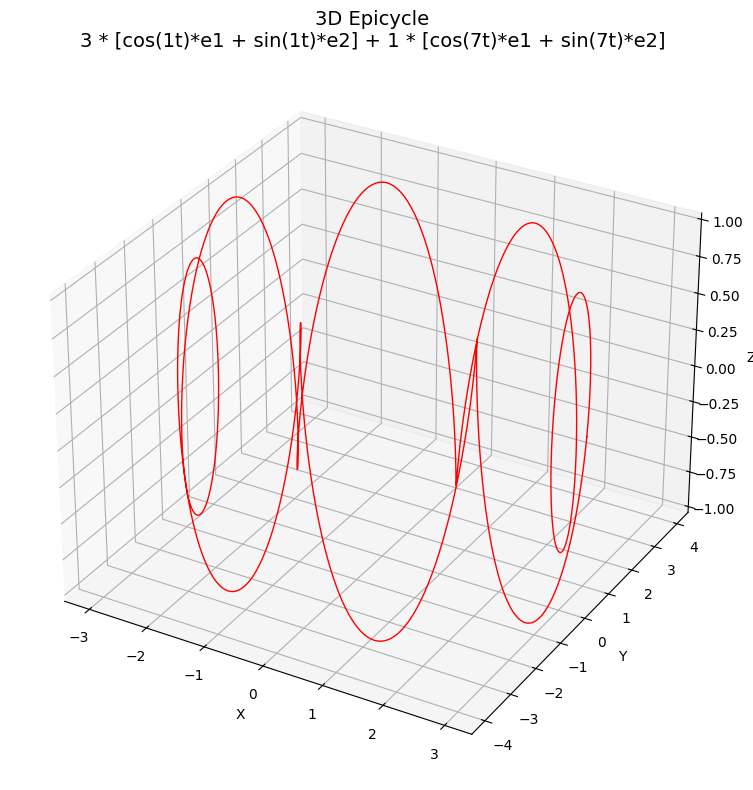

In [17]:
# 3D 外摆线
epicycle3d = Rotor3D(3, 1, 0, [1,0,0], [0,1,0]) + Rotor3D(1, 7, 0, [0,1,0], [0,0,1])
t, x, y, z = trace_nd(epicycle3d, n_points=2000)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, 'r-', lw=1)
ax.set_title(f'3D Epicycle\n{epicycle3d}', fontsize=14)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.tight_layout()
plt.show()

## 7. 维度对比

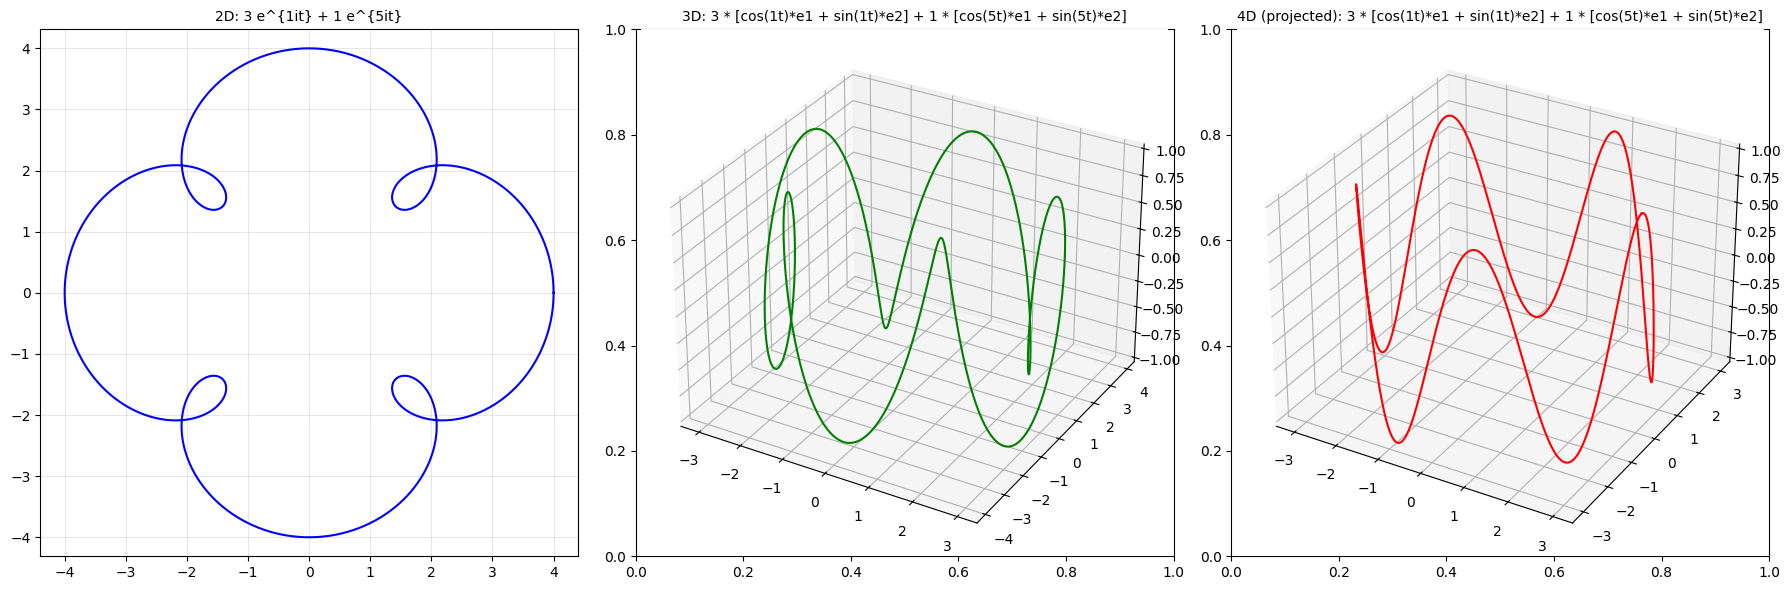

Same frequency composition in 2D, 3D, 4D


In [18]:
# 对比 2D, 3D, 4D 的相同频率组合
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 2D
curve2d = Rotor2D(3, 1) + Rotor2D(1, 5)
t, x, y = trace(curve2d, n_points=1000)
axes[0].plot(x, y, 'b-', lw=1.5)
axes[0].set_title(f'2D: {curve2d}', fontsize=10)
axes[0].axis('equal')
axes[0].grid(True, alpha=0.3)

# 3D
curve3d = Rotor3D(3, 1, 0, [1,0,0], [0,1,0]) + Rotor3D(1, 5, 0, [0,1,0], [0,0,1])
t, x, y, z = trace_nd(curve3d, n_points=1000)
ax3d = fig.add_subplot(132, projection='3d')
ax3d.plot(x, y, z, 'g-', lw=1.5)
ax3d.set_title(f'3D: {curve3d}', fontsize=10)

# 4D (投影到 3D)
curve4d = RotorClifford(3, 1, 0, [1,0,0,0], [0,1,0,0], n_dim=4) + RotorClifford(1, 5, 0, [0,0,1,0], [0,0,0,1], n_dim=4)
t, x, y, z, w = trace_nd(curve4d, n_points=1000)
ax4d = fig.add_subplot(133, projection='3d')
ax4d.plot(x, y, z, 'r-', lw=1.5)
ax4d.set_title(f'4D (projected): {curve4d}', fontsize=10)

plt.tight_layout()
plt.show()

print("Same frequency composition in 2D, 3D, 4D")

## 总结

本 Notebook 演示了：

1. **Rotor3D** — 四元数 3D 旋转器，支持代数运算、频率分析
2. **RotorClifford** — Clifford 代数 nD 旋转器，支持任意维度
3. **几何分析** — 曲率 (GA 公式)、挠率 (3D)、弧长
4. **可视化** — matplotlib 3D / plotly 3D 双后端
5. **经典曲线** — 螺旋线、外摆线、维度对比

---

**数学统一性**：
- 2D: 复数 $e^{i\theta}$
- 3D: 四元数 $\exp(-B\theta/2)$
- nD: Clifford rotor $\exp(-B\theta/2)$

所有维度使用相同的 CPR 理论框架：
$$
\gamma(t) = \text{center} + \sum R_k(t)
$$

---

**CPR = Circle Point Round Dot Surface Pyramid**

*Geometry by Composition of Motion.*